# 01 · Simulator calibration (Phase 2, step 2)

**Goal.** Measure, from real OBD-II data, the numbers the simulator needs so its output
looks like real cars and real devices: trip patterns, sampling cadence and dropouts,
engine warm-up, idle noise, the airflow relationship, and fuel-trim spread.

**Inputs** (read-only, from `DATASETS_DIR/raw`, see `ml/data_cards/`):

| Dataset | Used for |
|---|---|
| VED (264 petrol cars, Michigan, 2017–18) | trip length/duration, trips and km per day, idle share, start hours, MAF physics check, fuel trims |
| KIT (1 Seat Leon, Germany, 2017) | coolant warm-up curve, round-robin polling cadence, warm-idle RPM noise, traffic vs free-flow |
| Barreto exp1 (14 cars, Brazil, 2003–2016) | ELM327-style sampling rate, dropouts, which PIDs older cars lack, a 2009 Toyota Corolla trace |

**Outputs**
- `simulator/profiles/calibration.yaml`: every number, with its source.
- `ml/reports/phase2_calibration.md`: the same numbers, with how far each is from Lagos.
- Cache: `DATASETS_DIR/interim/ved_trip_stats.parquet` (regenerated if missing).

**Rule for this whole notebook:** results are summarised with **medians and percentiles**,
not means. One broken sensor or a 9-hour "trip" would drag a mean far off; the median
(the middle value) and the 10th/90th percentiles barely move.

In [1]:
import math, os, re, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from scipy.optimize import curve_fit

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve().parent
load_dotenv(REPO / ".env")
DATASETS_DIR = Path(os.environ["DATASETS_DIR"])
RAW = DATASETS_DIR / "raw"
INTERIM = DATASETS_DIR / "interim"
REBUILD_CACHE = os.environ.get("REBUILD_CACHE", "0") == "1"

assert (RAW / "ved").is_dir() and (RAW / "kit_obd").is_dir() and (RAW / "barreto_obd").is_dir(), RAW
pd.set_option("display.width", 140, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7, 3.2)})

def pct(s, ps=(10, 50, 90), nd=2):
    s = pd.Series(s).dropna()
    return {f"p{p}": round(float(np.percentile(s, p)), nd) for p in ps} | {"n": int(len(s))}

CAL = {}       # everything that goes into calibration.yaml
SOURCES = {}   # value path -> where it came from (for the report)
print("repo:", REPO.name, "| datasets:", DATASETS_DIR.name, "| raw datasets:", sorted(p.name for p in RAW.iterdir() if p.is_dir()))

repo: mycar | datasets: datasets | raw datasets: ['barreto_obd', 'kit_obd', 'ved']


## 1 · VED: how petrol cars are used

VED logs every trip of 383 cars for a year. We keep the **264 petrol (ICE)** cars and
summarise each trip into one row.

**Gap handling.** Samples arrive about once a second, but sometimes the logger misses
seconds or minutes. When integrating speed into distance we only use steps of at most
10 s; a longer hole is a *gap* and isn't bridged (we'd be guessing what happened inside
it). That's the same rule the backend will use in Phase 3.

**Idle share** = time at < 2 km/h with the engine running ÷ trip time, counting time
(not rows), so a burst of fast logging doesn't weigh more than a slow stretch.

In [2]:
# Static data: which cars are petrol, and their engine size.
st = pd.read_excel(RAW / "ved/static/VED_Static_Data_ICE&HEV.xlsx")
st = st.rename(columns={"VehId": "veh", "Vehicle Type": "vtype",
                        "Engine Configuration & Displacement": "engine"})
eng = st["engine"].astype(str).str.extract(r"^(?P<cyl>\d+)-\w+\s+(?P<disp>[\d.]+)L(?P<rest>.*)$")
st["cyl"] = pd.to_numeric(eng["cyl"], errors="coerce")
st["disp_l"] = pd.to_numeric(eng["disp"], errors="coerce")
st["turbo"] = eng["rest"].fillna("").str.contains("T/C")
ice = st[st.vtype == "ICE"][["veh", "cyl", "disp_l", "turbo"]].copy()
print(f"{len(ice)} ICE cars; displacement known for {ice.disp_l.notna().sum()}; turbo {ice.turbo.sum()}")
ice.disp_l.describe().round(2)

264 ICE cars; displacement known for 241; turbo 18


count    241.00
mean       2.73
std        0.96
min        1.40
25%        2.00
50%        2.40
75%        3.50
max        6.80
Name: disp_l, dtype: float64

In [3]:
GAP_S = 10.0          # longer steps are gaps, not integrated
RHO_AIR = 1.184       # g/L, air at 25 °C, sea level
COLS = {"VehId": "veh", "Trip": "trip", "DayNum": "day", "Timestamp(ms)": "t_ms",
        "Vehicle Speed[km/h]": "speed", "Engine RPM[RPM]": "rpm", "MAF[g/sec]": "maf",
        "Absolute Load[%]": "abs_load", "OAT[DegC]": "oat",
        "Short Term Fuel Trim Bank 1[%]": "stft", "Long Term Fuel Trim Bank 1[%]": "ltft"}
DISP = ice.set_index("veh")["disp_l"]

def ved_trip_stats(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, usecols=list(COLS), dtype="float64").rename(columns=COLS)
    df = df[df.veh.isin(DISP.index)].sort_values(["veh", "trip", "t_ms"], kind="stable")
    key = ["veh", "trip"]
    dt = df.groupby(key, sort=False)["t_ms"].diff().fillna(0) / 1000
    dtc = dt.where(dt <= GAP_S, 0.0)
    engine_on = df.rpm.isna() | (df.rpm > 300)
    df = df.assign(
        dt=dt, dtc=dtc,
        dist=df.speed.fillna(0) / 3600 * dtc,
        idle=dtc.where((df.speed < 2) & engine_on, 0.0),
        gap=(dt > GAP_S).astype(int),
        # MAF predicted from absolute load (PID 43 is defined as air mass per intake stroke
        # relative to a full cylinder of air): MAF = load × ρ × displacement × RPM/120.
        maf_ratio=df.maf / (df.abs_load / 100 * RHO_AIR * df.veh.map(DISP) * df.rpm / 120),
    )
    g = df.groupby(key, sort=False)
    out = g.agg(start_day=("day", "min"), t_start=("t_ms", "min"), t_end=("t_ms", "max"),
                n=("t_ms", "size"), dist_km=("dist", "sum"), idle_s=("idle", "sum"),
                covered_s=("dtc", "sum"), gaps=("gap", "sum"), max_step_s=("dt", "max"),
                step_med_s=("dt", "median"), oat=("oat", "median"))
    ok = (df.rpm > 800) & (df.abs_load > 10) & (df.maf > 0) & np.isfinite(df.maf_ratio)
    out["maf_ratio"] = df[ok].groupby(key)["maf_ratio"].median()
    warm = (df.t_ms >= 8 * 60_000) & (df.speed > 10)       # well into the trip, moving
    out["stft_med"] = df[warm].groupby(key)["stft"].median()
    out["ltft_med"] = df[warm].groupby(key)["ltft"].median()
    return out.reset_index()

cache = INTERIM / "ved_trip_stats.parquet"
if cache.exists() and not REBUILD_CACHE:
    trips = pd.read_parquet(cache)
    print(f"loaded cache {cache.name}: {len(trips)} trips")
else:
    t0 = time.time()
    files = sorted((RAW / "ved/dynamic").glob("*/*.csv"))
    trips = pd.concat([ved_trip_stats(f) for f in files], ignore_index=True)
    INTERIM.mkdir(exist_ok=True)
    trips.to_parquet(cache, index=False)
    print(f"processed {len(files)} files in {time.time() - t0:.0f} s -> {len(trips)} trips")
trips["duration_min"] = (trips.t_end - trips.t_start) / 60_000
trips["idle_share"] = trips.idle_s / trips.covered_s.where(trips.covered_s > 0)
# DayNum counts days from 2017-11-01 00:00. Is that UTC or Michigan time? The data says UTC:
# read as local time, the quietest hours would be 05:00-08:00 (implausible); read as UTC
# and shifted to America/Detroit, the quietest hours are ~01:00-04:00. Checked below.
start_utc = pd.Timestamp("2017-11-01", tz="UTC") + pd.to_timedelta(trips.start_day - 1, unit="D")
local = start_utc.dt.tz_convert("America/Detroit")
naive_hours = ((trips.start_day % 1) * 24).astype(int)
quietest = lambda h: h.value_counts().reindex(range(24), fill_value=0).rolling(3).sum().idxmin() - 1  # noqa: E731
print(f"quietest hour if DayNum were local: {quietest(naive_hours):02d}:00; "
      f"as UTC -> Detroit: {quietest(local.dt.hour):02d}:00")
trips["start_hour"] = local.dt.hour
trips["date"] = local.dt.date
trips[["duration_min", "dist_km", "idle_share", "gaps", "step_med_s"]].describe(
    percentiles=[.1, .5, .9]).round(2)

loaded cache ved_trip_stats.parquet: 18936 trips
quietest hour if DayNum were local: 07:00; as UTC -> Detroit: 02:00


,duration_min,dist_km,idle_share,gaps,step_med_s
count,18936.00,18936.00,18936.00,18936.00,18936.00
mean,8.69,5.04,0.20,0.07,0.64
std,8.00,4.24,0.15,0.69,0.18
min,0.16,0.00,0.00,0.00,0.20
10%,2.07,1.22,0.00,0.00,0.40
50%,6.76,4.05,0.19,0.00,0.70
90%,16.87,9.73,0.39,0.00,0.80
max,168.68,110.48,1.00,32.00,3.10


18824 of 18936 trips kept (112 dropped as artefacts)
trip_duration_min        {'p10': 2.1, 'p50': 6.8, 'p90': 16.9, 'n': 18824}
trip_distance_km         {'p10': 1.3, 'p50': 4.1, 'p90': 9.8, 'n': 18824}
idle_share               {'p10': 0.0, 'p50': 0.191, 'p90': 0.388, 'n': 18824}
km_per_driving_day       {'p10': 1.4, 'p50': 5.2, 'p90': 14.3, 'n': 13976}


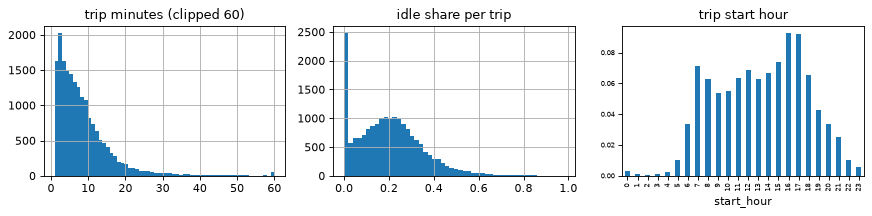

In [4]:
# Keep plausible trips: at least 1 min and 0.2 km; drop multi-hour logging artefacts.
real = trips[(trips.duration_min >= 1) & (trips.dist_km >= 0.2) & (trips.duration_min <= 240)]
print(f"{len(real)} of {len(trips)} trips kept ({len(trips) - len(real)} dropped as artefacts)")

days = real.groupby(["veh", "date"]).agg(trips=("trip", "size"), km=("dist_km", "sum"))
hours = real.start_hour.value_counts(normalize=True).reindex(range(24), fill_value=0)
hours_driven = (real.covered_s.sum() / 3600)

CAL["usage_ved"] = {
    "trip_duration_min": pct(real.duration_min, nd=1),
    "trip_distance_km": pct(real.dist_km, nd=1),
    "idle_share": pct(real.idle_share, nd=3),
    "trips_per_driving_day": pct(days.trips, nd=1),
    "km_per_driving_day": pct(days.km, nd=1),
    "start_hour_share": [round(float(x), 4) for x in hours],
    "gaps_per_driving_hour": round(float(real.gaps.sum() / hours_driven), 2),
    "sample_step_s": pct(real.step_med_s, nd=2),
}
SOURCES["usage_ved"] = "VED dynamic, 264 ICE cars, per-trip aggregation (section 1)"
for k in ("trip_duration_min", "trip_distance_km", "idle_share", "km_per_driving_day"):
    print(f"{k:24s}", CAL["usage_ved"][k])

fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
real.duration_min.clip(upper=60).hist(bins=60, ax=ax[0]); ax[0].set_title("trip minutes (clipped 60)")
real.idle_share.hist(bins=50, ax=ax[1]); ax[1].set_title("idle share per trip")
hours.plot.bar(ax=ax[2]); ax[2].set_title("trip start hour"); ax[2].tick_params(labelsize=6)
plt.tight_layout()

### 1b · Airflow physics check and fuel trims

The simulator computes MAF (grams of air per second) from engine speed and load:

  **MAF = (absolute load / 100) × ρ_air × displacement × RPM / 120**

RPM/120 is intake strokes per second per litre (a 4-stroke engine fills each cylinder
every 2 turns), and absolute load (PID 0x43) is defined as how full each cylinder is
relative to a full charge of standard air. If the formula is right, real `MAF ÷ predicted`
should sit near 1.0. Its spread tells the simulator how much noise to add.

Fuel trims are the ECU's fuel corrections, in %. Healthy engines sit within a few % of
zero; a drift is an early sign of leaks or a dirty MAF (Phase 5). Here we only need
their *normal* spread between cars.

In [5]:
by_car = real.groupby("veh").agg(maf_ratio=("maf_ratio", "median"),
                                 stft=("stft_med", "median"), ltft=("ltft_med", "median"))
CAL["airflow"] = {
    "maf_over_predicted_per_car": pct(by_car.maf_ratio, nd=3),
    "maf_over_predicted_per_trip_spread": pct(real.maf_ratio, (10, 25, 50, 75, 90), nd=3),
}
CAL["fuel_trim_ved"] = {
    "stft_b1_pct_per_car": pct(by_car.stft, nd=2),
    "ltft_b1_pct_per_car": pct(by_car.ltft, nd=2),
}
SOURCES["airflow"] = "VED ICE, samples with RPM>800, load>10 %, MAF>0 (section 1b)"
SOURCES["fuel_trim_ved"] = "VED ICE, ≥8 min into trip and moving >10 km/h (section 1b)"
print("MAF / predicted, per car:", CAL["airflow"]["maf_over_predicted_per_car"])
print("STFT per car:", CAL["fuel_trim_ved"]["stft_b1_pct_per_car"])
print("LTFT per car:", CAL["fuel_trim_ved"]["ltft_b1_pct_per_car"])

MAF / predicted, per car: {'p10': 0.965, 'p50': 1.004, 'p90': 1.018, 'n': 148}
STFT per car: {'p10': -0.78, 'p50': 0.0, 'p90': 1.25, 'n': 245}
LTFT per car: {'p10': -3.12, 'p50': 0.78, 'p90': 6.25, 'n': 241}


## 2 · KIT: warm-up, polling cadence, idle noise

KIT is one Seat Leon logged on 81 trips with a fast scan tool. Each row updates **one**
PID in turn (round-robin) and repeats the others, which is exactly how the Freematics
device will poll: one request at a time.

**First-order warm-up model.** A cold engine's coolant temperature rises quickly at first,
then levels off at the thermostat temperature. That shape is

  **T(t) = T_final − (T_final − T_start) · e^(−t/τ)**

where τ ("tau", the *time constant*) is how long it takes to cover ~63 % of the way.
A stuck-open thermostat shows up as a lower T_final and a longer time to reach it,
which is one of the simulator's faults (step 4). We fit τ and T_final on every cold start.

In [6]:
KIT_MAP = {"Coolant": "coolant", "Manifold": "map", "Engine RPM": "rpm", "Speed": "speed",
           "Intake Air": "iat", "Mass Flow": "maf", "Throttle": "throttle", "Ambient": "ambient",
           "Pedal Position D": "pedal_d", "Pedal Position E": "pedal_e"}

def kit_load(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, encoding="latin-1")
    ren = {"Time": "time"}
    for col in df.columns:
        for key, name in KIT_MAP.items():
            if key in col:
                ren[col] = name
    df = df.rename(columns=ren)
    t = pd.to_timedelta(df["time"], errors="coerce").dt.total_seconds()
    t = t + 86400 * (t.diff() < -3600).cumsum()          # past midnight
    df["t"] = t - t.iloc[0]
    parts = path.stem.split("_")
    df.attrs["condition"] = parts[-1] if parts[-1] not in ("Messfehler",) else "Messfehler"
    df.attrs["tags"] = parts[5:]
    return df

kit = {p.stem: kit_load(p) for p in sorted((RAW / "kit_obd").glob("*.csv"))}
kit = {k: v for k, v in kit.items() if "Messfehler" not in v.attrs["tags"]}   # measurement error
row_ms = pd.concat([v.t.diff().dropna() * 1000 for v in kit.values()])
n_signals = len(KIT_MAP)
CAL["polling_kit"] = {
    "row_interval_ms": pct(row_ms, nd=0),
    "signals_in_rotation": n_signals,
    "per_signal_refresh_s_est": round(float(row_ms.median() * n_signals / 1000), 2),
}
SOURCES["polling_kit"] = "KIT, 80 trips (measurement-error trip excluded); refresh = row interval × 10 PIDs"
print(len(kit), "KIT trips;", CAL["polling_kit"])

80 KIT trips; {'row_interval_ms': {'p10': 61.0, 'p50': 90.0, 'p90': 119.0, 'n': 2634110}, 'signals_in_rotation': 10, 'per_signal_refresh_s_est': 0.9}


66 cold starts fitted; 15 hit a bound; 30 kept (RMSE < 4 C)


      tau_s  t_final  time_to_80_s  ambient  rmse
50%   436.6     95.2         581.6     17.5   3.0
min   239.5     64.6         376.1    -10.0   1.9
max  1055.3    107.1        2014.9     24.0   4.0


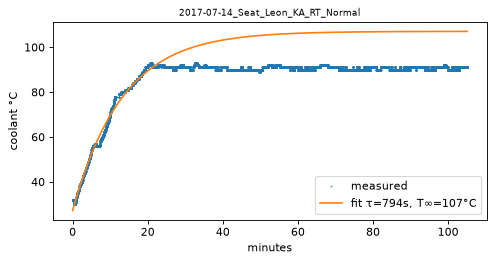

In [7]:
def warmup(t, t_final, tau, t_start):
    return t_final - (t_final - t_start) * np.exp(-t / tau)

fits = []
for name, df in kit.items():
    c = df[["t", "coolant", "ambient"]].dropna(subset=["coolant"])
    if c.empty or c.coolant.iloc[0] > 45:          # cold starts only
        continue
    w = c[c.t <= 1500]
    try:
        (tf, tau, ts), _ = curve_fit(warmup, w.t, w.coolant, p0=(90, 300, w.coolant.iloc[0]),
                                     bounds=([60, 20, -20], [115, 5000, 60]), maxfev=10_000)
    except RuntimeError:
        continue
    hit = c[c.coolant >= 80]
    fits.append({"trip": name, "t_final": tf, "tau_s": tau, "t_start": ts,
                 "ambient": c.ambient.median(), "time_to_80_s": hit.t.iloc[0] if len(hit) else np.nan,
                 "rmse": float(np.sqrt(np.mean((warmup(w.t, tf, tau, ts) - w.coolant) ** 2)))})
fits = pd.DataFrame(fits)
# A fit that ends on a bound (T_final 60/115 °C, τ 20/5000 s) didn't converge to a real
# value: usually the coolant hadn't levelled off inside 25 min (cold ambient). Drop those.
at_bound = (fits.t_final > 114) | (fits.t_final < 61) | (fits.tau_s > 4900) | (fits.tau_s < 21)
good = fits[(fits.rmse < 4) & ~at_bound]
print(f"{len(fits)} cold starts fitted; {at_bound.sum()} hit a bound; {len(good)} kept (RMSE < 4 C)")

# The thermostat set-point is read from the measured plateau, not from T_final: a single
# exponential overshoots it, because the real curve rises then *clamps* when the
# thermostat opens. T_final is kept only as a fit diagnostic.
warm_coolant = pd.concat([d.loc[d.t > 1200, "coolant"] for d in kit.values()]).dropna()
CAL["thermal_kit"] = {
    "warmup_tau_s": pct(good.tau_s, nd=0),
    "warmup_fit_t_final_c_diagnostic": pct(good.t_final, nd=1),
    "time_to_80c_s": pct(good.time_to_80_s, nd=0),
    "ambient_c_during_fits": pct(good.ambient, nd=1),
    "coolant_after_20min_c": pct(warm_coolant, (5, 50, 95), nd=1),
    "thermostat_plateau_c": round(float(warm_coolant.median()), 1),
}
SOURCES["thermal_kit"] = ("KIT cold starts (first coolant ≤ 45 °C), first 25 min fitted, fits at a "
                          "bound dropped; plateau = median coolant after 20 min (section 2)")
print(good[["tau_s", "t_final", "time_to_80_s", "ambient", "rmse"]].describe().round(1).loc[["50%", "min", "max"]])

ex = good.sort_values("rmse").iloc[0]
c = kit[ex.trip][["t", "coolant"]].dropna()
plt.plot(c.t / 60, c.coolant, ".", ms=1, label="measured")
tt = np.linspace(0, c.t.max(), 300)
plt.plot(tt / 60, warmup(tt, ex.t_final, ex.tau_s, ex.t_start), label=f"fit τ={ex.tau_s:.0f}s, T∞={ex.t_final:.0f}°C")
plt.xlabel("minutes"); plt.ylabel("coolant °C"); plt.legend(); plt.title(ex.trip, fontsize=8);

In [8]:
# Warm idle: standing still with a warm engine. Spread of RPM there = idle "noise".
idle_rows, cond_rows = [], []
for name, df in kit.items():
    w = df[(df.speed == 0) & (df.coolant >= 80) & (df.rpm > 400)]
    if len(w) > 50:
        idle_rows.append({"trip": name, "rpm_mean": w.rpm.mean(), "rpm_std": w.rpm.std(),
                          "maf_mean": w.maf.mean()})
    dt = df.t.diff().clip(upper=10).fillna(0)
    cond_rows.append({"condition": df.attrs["tags"][-1] if df.attrs["tags"] else "?",
                      "idle_share": float(dt[df.speed < 2].sum() / max(dt.sum(), 1)),
                      # Jams are often crawling, not standing: time under 10 km/h
                      "crawl_share": float(dt[df.speed < 10].sum() / max(dt.sum(), 1)),
                      "coolant_p95": df.coolant.quantile(.95)})
idle = pd.DataFrame(idle_rows)
cond = pd.DataFrame(cond_rows)
cond = cond[cond.condition.isin(["Normal", "Frei", "Stau"])]
CAL["idle_kit"] = {"warm_idle_rpm": pct(idle.rpm_mean, nd=0), "warm_idle_rpm_std": pct(idle.rpm_std, nd=1),
                   "warm_idle_maf_gs": pct(idle.maf_mean, nd=2)}
CAL["traffic_kit"] = {c: {"idle_share": round(float(g.idle_share.median()), 3),
                          "crawl_share_lt10kmh": round(float(g.crawl_share.median()), 3),
                          "coolant_p95_c": round(float(g.coolant_p95.median()), 1), "trips": int(len(g))}
                      for c, g in cond.groupby("condition")}
SOURCES["idle_kit"] = "KIT, speed 0, coolant ≥ 80 °C, RPM > 400 (section 2)"
SOURCES["traffic_kit"] = "KIT file-name tags Stau/Frei/Normal; meaning unconfirmed and results contradict it, so not used (section 2)"
print(CAL["idle_kit"]); print(CAL["traffic_kit"])

{'warm_idle_rpm': {'p10': 789.0, 'p50': 814.0, 'p90': 843.0, 'n': 74}, 'warm_idle_rpm_std': {'p10': 59.0, 'p50': 85.9, 'p90': 113.7, 'n': 74}, 'warm_idle_maf_gs': {'p10': 7.01, 'p50': 7.39, 'p90': 7.79, 'n': 74}}
{'Frei': {'idle_share': 0.185, 'crawl_share_lt10kmh': 0.249, 'coolant_p95_c': 91.0, 'trips': 12}, 'Normal': {'idle_share': 0.109, 'crawl_share_lt10kmh': 0.158, 'coolant_p95_c': 91.0, 'trips': 55}, 'Stau': {'idle_share': 0.125, 'crawl_share_lt10kmh': 0.196, 'coolant_p95_c': 91.0, 'trips': 10}}


## 3 · Barreto: what a cheap ELM327 logger on older cars looks like

Barreto's experiment 1 logged 14 cars (2003–2016, close to the Nigerian import fleet)
with a phone + ELM327 Bluetooth adapter. Values need cleaning: Brazilian decimal commas,
units glued to numbers (`82C`, `2124RPM`), percent strings.

We measure: the sampling step, **dropouts** (silences of 30 s to 10 min inside a
session), and which PIDs each car simply doesn't report. That last one drives the
simulator's capability switches, and it's why the PRD insists on "say so in the UI"
rather than showing a false "all good".

In [9]:
b = pd.read_csv(RAW / "barreto_obd/exp1_14drivers_14cars_dailyRoutes.csv", dtype=str)
b = b[b.VEHICLE_ID.notna()].copy()
NUM = ["ENGINE_COOLANT_TEMP", "ENGINE_LOAD", "ENGINE_RPM", "SPEED", "MAF", "INTAKE_MANIFOLD_PRESSURE",
       "SHORT TERM FUEL TRIM BANK 1", "LONG TERM FUEL TRIM BANK 2", "THROTTLE_POS", "TIMING_ADVANCE",
       "AIR_INTAKE_TEMP", "FUEL_LEVEL", "BAROMETRIC_PRESSURE(KPA)", "AMBIENT_AIR_TEMP"]

def to_num(s: pd.Series) -> pd.Series:
    x = s.str.replace(",", ".", regex=False).str.extract(r"(-?\d+(?:\.\d+)?)")[0]
    return pd.to_numeric(x, errors="coerce")

for col in NUM:
    b[col] = to_num(b[col])
b["ts"] = pd.to_numeric(b.TIMESTAMP, errors="coerce") / 1000
b = b.dropna(subset=["ts"]).sort_values(["VEHICLE_ID", "ts"])
b["dt"] = b.groupby("VEHICLE_ID").ts.diff()
b["session"] = (b.dt.isna() | (b.dt > 600)).groupby(b.VEHICLE_ID).cumsum()
inside = b[b.dt <= 600]
hours = inside.groupby("VEHICLE_ID").dt.sum() / 3600
drop = inside[inside.dt > 30]

cars = b.groupby("VEHICLE_ID").agg(make=("MARK", "first"), model=("MODEL", "first"),
                                   year=("CAR_YEAR", "first"), rows=("ts", "size"))
cars["step_med_s"] = inside.groupby("VEHICLE_ID").dt.median()
cars["dropouts_per_h"] = drop.groupby("VEHICLE_ID").size().reindex(cars.index, fill_value=0) / hours
avail = b.groupby("VEHICLE_ID")[NUM].apply(lambda d: d.notna().mean())
cars["pids_missing"] = (avail < 0.05).sum(axis=1)
print(cars.round(2).to_string())

CAL["sampling_barreto"] = {
    "step_s_per_car": pct(cars.step_med_s, nd=1),
    "dropouts_per_hour_per_car": pct(cars.dropouts_per_h, nd=2),
    "dropout_duration_s": pct(drop.dt, nd=0),
    "share_of_14_core_pids_missing_per_car": pct(cars.pids_missing / len(NUM), nd=2),
    "least_available_pids": avail.mean().sort_values().head(5).round(2).to_dict(),
}
SOURCES["sampling_barreto"] = "Barreto exp1, 14 cars; sessions split at silences > 10 min (section 3)"
CAL["sampling_barreto"]

                  make       model  year   rows  step_med_s  dropouts_per_h  pids_missing
VEHICLE_ID                                                                               
car1         chevrolet       agile  2011  13617        4.01           20.53             0
car10             fiat       siena  2010      7        8.01            0.00             5
car11           toyota     corolla  2009   7485        8.01            4.59             4
car12           nissan       versa  2016   1866        8.03           11.67             4
car13          citroen          c3  2013   2060        6.96           10.91             5
car14       volkswagen      voyage  2013    180       12.03            1.39             5
car2              ford   eco_sport  2010    138        4.01            0.00             3
car3             honda         fit  2005    903        8.01            0.00             5
car4           renault      duster  2012   2920        8.01            0.00             5
car5      

{'step_s_per_car': {'p10': 4.9, 'p50': 8.0, 'p90': 11.1, 'n': 14},
 'dropouts_per_hour_per_car': {'p10': 0.0, 'p50': 0.91, 'p90': 11.44, 'n': 14},
 'dropout_duration_s': {'p10': 33.0, 'p50': 49.0, 'p90': 134.0, 'n': 1006},
 'share_of_14_core_pids_missing_per_car': {'p10': 0.24,
  'p50': 0.36,
  'p90': 0.36,
  'n': 14},
 'least_available_pids': {'AMBIENT_AIR_TEMP': 0.08,
  'BAROMETRIC_PRESSURE(KPA)': 0.09,
  'FUEL_LEVEL': 0.09,
  'MAF': 0.15,
  'LONG TERM FUEL TRIM BANK 2': 0.22}}

In [10]:
cor = b[b.MODEL.str.lower().eq("corolla")]
warm = cor[(cor.ENGINE_COOLANT_TEMP >= 80)]
idle_c = warm[warm.SPEED == 0]
CAL["corolla_2009_barreto"] = {
    "rows": int(len(cor)),
    "warm_idle_rpm": pct(idle_c.ENGINE_RPM, nd=0),
    "warm_idle_load_pct": pct(idle_c.ENGINE_LOAD, nd=1),
    "coolant_warm_c": pct(warm.ENGINE_COOLANT_TEMP, nd=0),
    "stft_b1_pct": pct(warm["SHORT TERM FUEL TRIM BANK 1"], nd=1),
    "note": "Brazilian Corolla 2009 is likely flex-fuel (ethanol blends): trims not comparable to petrol",
}
SOURCES["corolla_2009_barreto"] = "Barreto exp1, the one Toyota Corolla 2009 (section 3)"

codes = b[b.TROUBLE_CODES.notna()].groupby(["VEHICLE_ID", "MARK", "MODEL"]).TROUBLE_CODES.agg(
    lambda s: s.value_counts().head(3).to_dict())
print("Corolla:", {k: v for k, v in CAL["corolla_2009_barreto"].items() if k != "note"})
print("\nTrouble codes seen (rows):"); print(codes.to_string())

Corolla: {'rows': 7485, 'warm_idle_rpm': {'p10': 635.0, 'p50': 746.0, 'p90': 875.0, 'n': 500}, 'warm_idle_load_pct': {'p10': 32.9, 'p50': 38.4, 'p90': 48.6, 'n': 500}, 'coolant_warm_c': {'p10': 85.0, 'p50': 86.0, 'p90': 93.0, 'n': 7171}, 'stft_b1_pct': {'p10': -6.0, 'p50': 0.0, 'p90': 5.0, 'n': 7162}}

Trouble codes seen (rows):
VEHICLE_ID  MARK        MODEL     
car13       citroen     c3            {'P0079P2004P3000': 48, 'P0079C1004P3000': 30,...
car6        volkswagen  polo                                            {'P0133': 6070}
car9        peugeot     208_allure                                      {'C0300': 5673}


## 4 · Write `calibration.yaml` and the report

Every value carries its source. Values with **no** dataset behind them (Lagos traffic,
heat, fuel quality) stay in the simulator's SEED profile files and are listed in the
report as still unvalidated.

In [11]:
def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if not math.isfinite(float(x)) else round(float(x), 4)
    return x

out = {
    "generated_by": "ml/notebooks/01_simulator_calibration.ipynb",
    "generated_at": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%MZ"),
    "datasets": {"ved": "raw/ved (checksums in CHECKSUMS.txt)", "kit": "raw/kit_obd",
                 "barreto": "raw/barreto_obd"},
    "sources": SOURCES,
    **jsonable(CAL),
}
cal_path = REPO / "simulator/profiles/calibration.yaml"
cal_path.parent.mkdir(parents=True, exist_ok=True)
header = ("# GENERATED by ml/notebooks/01_simulator_calibration.ipynb - do not edit by hand.\n"
          "# Measured on US (VED), German (KIT) and Brazilian (Barreto) data: shape priors, not Lagos truth.\n")
cal_path.write_text(header + yaml.safe_dump(out, sort_keys=False, allow_unicode=True), encoding="utf-8", newline="\n")
print("wrote", cal_path.relative_to(REPO), f"({cal_path.stat().st_size} bytes)")

wrote simulator\profiles\calibration.yaml (4420 bytes)


In [12]:
U, T, I, S, A = CAL["usage_ved"], CAL["thermal_kit"], CAL["idle_kit"], CAL["sampling_barreto"], CAL["airflow"]
rows = [
    ("Trip duration (min)", U["trip_duration_min"], "VED", "Lagos trips are likely longer in time for the same distance (congestion)."),
    ("Trip distance (km)", U["trip_distance_km"], "VED", "Similar order; Lagos commutes can be long."),
    ("Idle share per trip", U["idle_share"], "VED", "**Far lower than Lagos.** Lagos heavy-traffic stays a SEED (P2: 40–50 %)."),
    ("Trips per driving day", U["trips_per_driving_day"], "VED", "**Understated:** VED seems to hold only part of each car's trips. Not used; Lagos trips/day stay SEED."),
    ("km per driving day", U["km_per_driving_day"], "VED", "**Understated** for the same reason. Not used; Lagos km/day stays SEED."),
    ("Trip start hour (Detroit local)", "24-hour shares in calibration.yaml", "VED", "DayNum is UTC (checked in section 1); converted to Michigan time. Lagos rush hours stay SEED."),
    ("Logger sample step (s)", U["sample_step_s"], "VED", "Close to the planned 1 Hz fast group."),
    ("Gaps > 10 s per driving hour", U["gaps_per_driving_hour"], "VED", "Logger gaps, not cellular outages (P7 stays SEED)."),
    ("KIT row interval (ms)", CAL["polling_kit"]["row_interval_ms"], "KIT", "One PID per row; ~10 PIDs in rotation."),
    ("Per-signal refresh (s), est.", CAL["polling_kit"]["per_signal_refresh_s_est"], "KIT", "What a fast adapter achieves with 10 PIDs."),
    ("Warm-up τ (s)", T["warmup_tau_s"], "KIT", "German summer ambient; Lagos ambient ~30–35 °C shortens warm-up."),
    ("Thermostat plateau (°C)", T["thermostat_plateau_c"], "KIT", "Median coolant after 20 min; Toyota profiles stay SEED (P1)."),
    ("Time to 80 °C (s)", T["time_to_80c_s"], "KIT", ""),
    ("Coolant after 20 min, p5/p50/p95 (°C)", T["coolant_after_20min_c"], "KIT", "Lagos traffic idling should push p95 higher."),
    ("Warm idle RPM", I["warm_idle_rpm"], "KIT", "Seat Leon; Toyota idle RPM stays SEED (P1)."),
    ("Warm idle RPM std", I["warm_idle_rpm_std"], "KIT", "Baseline idle noise for the misfire fault."),
    ("KIT trip tags (Stau / Frei / Normal)", CAL["traffic_kit"], "KIT", "**Not usable:** 'Frei' trips idle and crawl *more* than 'Stau' (jam) trips, so the tags don't mean what the file names suggest (unconfirmed in the data card). No traffic conclusion drawn; P2 stays SEED."),
    ("MAF ÷ predicted, per car", A["maf_over_predicted_per_car"], "VED", "Checks the simulator's airflow formula."),
    ("LTFT B1 per car (%)", CAL["fuel_trim_ved"]["ltft_b1_pct_per_car"], "VED", "Normal spread between healthy cars."),
    ("ELM327 step per car (s)", S["step_s_per_car"], "Barreto", "Phone loggers are slow; Freematics should be ~1 Hz."),
    ("Dropouts per hour per car", S["dropouts_per_hour_per_car"], "Barreto", "Bluetooth/phone dropouts, a lower bound for cellular gaps."),
    ("Dropout duration (s)", S["dropout_duration_s"], "Barreto", ""),
    ("Share of 14 core PIDs missing per car", S["share_of_14_core_pids_missing_per_car"], "Barreto", "Drives capability switches."),
    ("Corolla 2009 warm idle RPM", CAL["corolla_2009_barreto"]["warm_idle_rpm"], "Barreto", "Flex-fuel Brazilian Corolla; closest to our Corolla profile."),
]
lines = [
    "# Phase 2 calibration report (simulator)",
    "",
    f"Generated by `ml/notebooks/01_simulator_calibration.ipynb` on {out['generated_at']}. "
    "Machine-readable values: `simulator/profiles/calibration.yaml`.",
    "",
    "**How to read this:** every number comes from a real dataset that is *not* Nigerian. "
    "They fix the simulator's *shapes* (how signals relate, how noisy they are, how loggers drop "
    "out). Where Lagos is clearly different, the simulator keeps a SEED value instead and the "
    "last column says so.",
    "",
    "| Quantity | Value | Source | Distance from Lagos / note |",
    "|---|---|---|---|",
]
for q, v, src, note in rows:
    lines.append(f"| {q} | `{jsonable(v)}` | {src} | {note} |")
lines += [
    "",
    "## Still SEED after this notebook (no data available)",
    "",
    "- P1 vehicle profiles (displacement, gear ratios, thermostat, supported PIDs for the five Toyota/Lexus/Honda models)",
    "- P2 Lagos heavy-traffic cycle (idle share 40–50 %, mean speed 12–18 km/h)",
    "- P3/P4 fault degradation rates and DTC timing",
    "- P7 cellular outage model (Nigerian coverage)",
    "",
    "## Sources",
    "",
] + [f"- `{k}`: {v}" for k, v in SOURCES.items()]
rep = REPO / "ml/reports/phase2_calibration.md"
rep.write_text("\n".join(lines) + "\n", encoding="utf-8", newline="\n")
print("wrote", rep.relative_to(REPO))

wrote ml\reports\phase2_calibration.md


## Limitations

- **None of this data is Nigerian.** Traffic, heat, fuel quality and road conditions in
  Lagos differ from Michigan, Karlsruhe and Natal. These numbers set relationships and
  noise; Lagos-specific levels stay SEED until the Phase 9 field test.
- VED's static file has no make/model/year, so the MAF and trim spreads are across a
  mixed US fleet, not per Toyota model.
- KIT is a single car; its warm-up τ describes one engine in summer.
- Barreto's cars run ethanol blends; their fuel trims and equivalence ratios aren't used.